<a href="https://colab.research.google.com/github/Shahin028/AIML_/blob/main/CASE_STUDY_shahin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

In [5]:
# Load the dataset

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/aiml/dataset/House_Pricing.csv")

# Display first 5 rows

df.head()

,ID,Date House was Sold,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Waterfront View,No of Times Visited,...,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft)
0,7129300520,14 October 2017,221900.0,3,1.00,1180.0,5650.0,1.0,No,NaN,...,7,1180.0,0,63,0,98178.0,47.5112,-122.257,1340.0,5650
1,6414100192,14 December 2017,538000.0,3,2.25,2570.0,7242.0,2.0,No,NaN,...,7,2170.0,400,67,1991,98125.0,47.7210,-122.319,1690.0,7639
2,5631500400,15 February 2016,180000.0,2,1.00,770.0,10000.0,1.0,No,NaN,...,6,770.0,0,85,0,98028.0,47.7379,-122.233,2720.0,8062
3,2487200875,14 December 2017,604000.0,4,3.00,1960.0,5000.0,1.0,No,NaN,...,7,1050.0,910,53,0,98136.0,47.5208,-122.393,1360.0,5000
4,1954400510,15 February 2016,510000.0,3,2.00,1680.0,8080.0,1.0,No,NaN,...,8,1680.0,0,31,0,98074.0,47.6168,-122.045,1800.0,7503


In [6]:
df.shape

(21613, 21)

In [7]:
#basic information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   ID                                         21613 non-null  int64  
 1   Date House was Sold                        21613 non-null  object 
 2   Sale Price                                 21609 non-null  float64
 3   No of Bedrooms                             21613 non-null  int64  
 4   No of Bathrooms                            21609 non-null  float64
 5   Flat Area (in Sqft)                        21604 non-null  float64
 6   Lot Area (in Sqft)                         21604 non-null  float64
 7   No of Floors                               21613 non-null  float64
 8   Waterfront View                            21613 non-null  object 
 9   No of Times Visited                        2124 non-null   object 
 10  Condition of the House

In [8]:
# Statistical summary of numerical columns

df.describe()

,ID,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Overall Grade,Area of the House from Basement (in Sqft),Basement Area (in Sqft),Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft)
count,2.161300e+04,2.160900e+04,21613.000000,21609.000000,21604.000000,2.160400e+04,21613.000000,21613.000000,21610.000000,21613.000000,21613.000000,21613.000000,21612.000000,21612.000000,21612.000000,21612.000000,21613.000000
mean,4.580302e+09,5.401984e+05,3.370842,2.114732,2079.931772,1.510776e+04,1.494309,7.623467,1788.344193,291.509045,46.994864,84.402258,98077.937766,47.560048,-122.213892,1986.538914,12768.455652
std,2.876566e+09,3.673890e+05,0.930062,0.770138,918.487597,4.142827e+04,0.539989,1.105439,827.982604,442.575043,29.373411,401.679240,53.505425,0.138565,0.140830,685.404255,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,1.000000,290.000000,0.000000,3.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1429.250000,5.040000e+03,1.000000,7.000000,1190.000000,0.000000,21.000000,0.000000,98033.000000,47.470975,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.617500e+03,1.500000,7.000000,1560.000000,0.000000,43.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068825e+04,2.000000,8.000000,2210.000000,560.000000,67.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,10.000000,9410.000000,4820.000000,118.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [9]:
# Check missing values

df.isnull().sum()

,0
ID,0
Date House was Sold,0
Sale Price,4
No of Bedrooms,0
No of Bathrooms,4
Flat Area (in Sqft),9
Lot Area (in Sqft),9
No of Floors,0
Waterfront View,0
No of Times Visited,19489


In [10]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Fill numerical missing values with median
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

In [11]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include="object").columns

# Fill categorical missing values with mode
for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [12]:
df.isnull().sum()

,0
ID,0
Date House was Sold,0
Sale Price,0
No of Bedrooms,0
No of Bathrooms,0
Flat Area (in Sqft),0
Lot Area (in Sqft),0
No of Floors,0
Waterfront View,0
No of Times Visited,0


In [13]:
# Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [14]:
df["Date House was Sold"] = pd.to_datetime(
    df["Date House was Sold"],
    errors="coerce"
)

In [15]:
df["Date House was Sold"].head()

,Date House was Sold
0,2017-10-14
1,2017-12-14
2,2016-02-15
3,2017-12-14
4,2016-02-15


In [16]:
df["Sale_Year"] = df["Date House was Sold"].dt.year
df["Sale_Month"] = df["Date House was Sold"].dt.month
df["Sale_Day"] = df["Date House was Sold"].dt.day

In [17]:
df.drop("Date House was Sold", axis=1, inplace=True)

In [18]:
df["Waterfront View"] = df["Waterfront View"].map({
    "Yes": 1,
    "No": 0
})

In [19]:
visit_mapping = {
    "Once": 1,
    "Twice": 2,
    "Thrice": 3,
    "Four": 4
}

df["No of Times Visited"] = df["No of Times Visited"].map(visit_mapping)

In [20]:
condition_mapping = {
    "Bad": 1,
    "Fair": 2,
    "Okay": 3,
    "Good": 4,
    "Excellent": 5
}

df["Condition of the House"] = df["Condition of the House"].map(
    condition_mapping
)

In [21]:
df.head()

,ID,Sale Price,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Lot Area (in Sqft),No of Floors,Waterfront View,No of Times Visited,Condition of the House,...,Age of House (in Years),Renovated Year,Zipcode,Latitude,Longitude,Living Area after Renovation (in Sqft),Lot Area after Renovation (in Sqft),Sale_Year,Sale_Month,Sale_Day
0,7129300520,221900.0,3,1.00,1180.0,5650.0,1.0,0,2,2,...,63,0,98178.0,47.5112,-122.257,1340.0,5650,2017,10,14
1,6414100192,538000.0,3,2.25,2570.0,7242.0,2.0,0,2,2,...,67,1991,98125.0,47.7210,-122.319,1690.0,7639,2017,12,14
2,5631500400,180000.0,2,1.00,770.0,10000.0,1.0,0,2,2,...,85,0,98028.0,47.7379,-122.233,2720.0,8062,2016,2,15
3,2487200875,604000.0,4,3.00,1960.0,5000.0,1.0,0,2,5,...,53,0,98136.0,47.5208,-122.393,1360.0,5000,2017,12,14
4,1954400510,510000.0,3,2.00,1680.0,8080.0,1.0,0,2,2,...,31,0,98074.0,47.6168,-122.045,1800.0,7503,2016,2,15


In [22]:
df.columns

Index(['ID', 'Sale Price', 'No of Bedrooms', 'No of Bathrooms',
       'Flat Area (in Sqft)', 'Lot Area (in Sqft)', 'No of Floors',
       'Waterfront View', 'No of Times Visited', 'Condition of the House',
       'Overall Grade', 'Area of the House from Basement (in Sqft)',
       'Basement Area (in Sqft)', 'Age of House (in Years)', 'Renovated Year',
       'Zipcode', 'Latitude', 'Longitude',
       'Living Area after Renovation (in Sqft)',
       'Lot Area after Renovation (in Sqft)', 'Sale_Year', 'Sale_Month',
       'Sale_Day'],
      dtype='object')

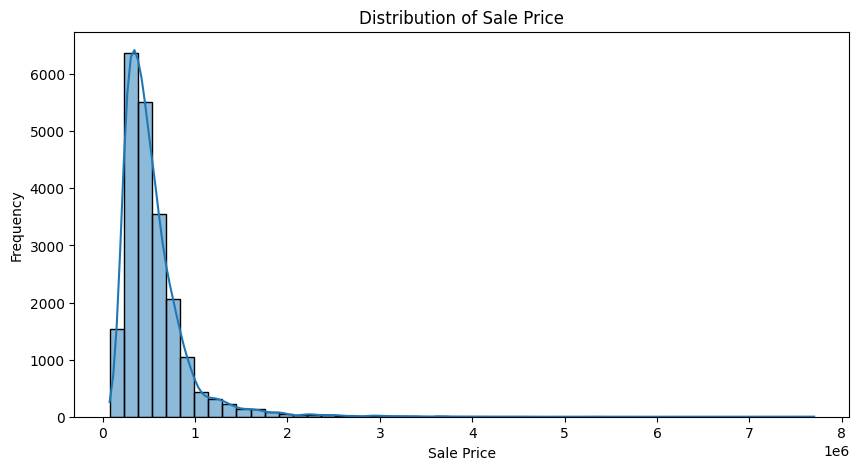

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Sale Price"], bins=50, kde=True)

plt.title("Distribution of Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

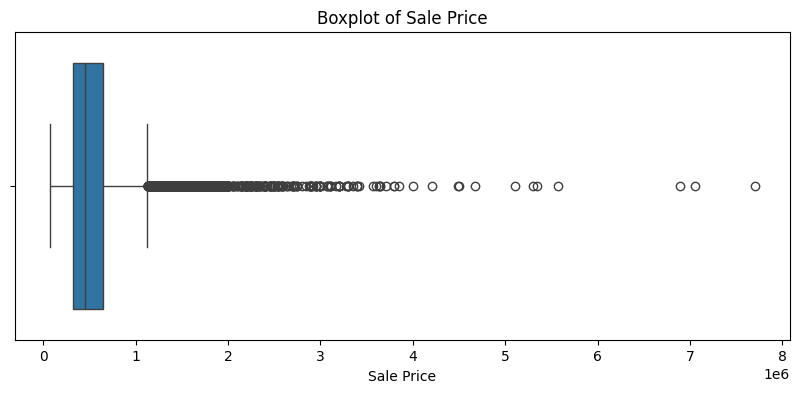

In [24]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Sale Price"])

plt.title("Boxplot of Sale Price")
plt.xlabel("Sale Price")

plt.show()

Conclusion
— Sale Price Distribution
The distribution of Sale Price is highly right-skewed, with most houses having relatively lower prices. A small number of houses have substantially higher sale prices.

— Sale Price Boxplot
The boxplot shows several high-value outliers in Sale Price. These observations indicate considerable variation in house prices and will be considered during model building.

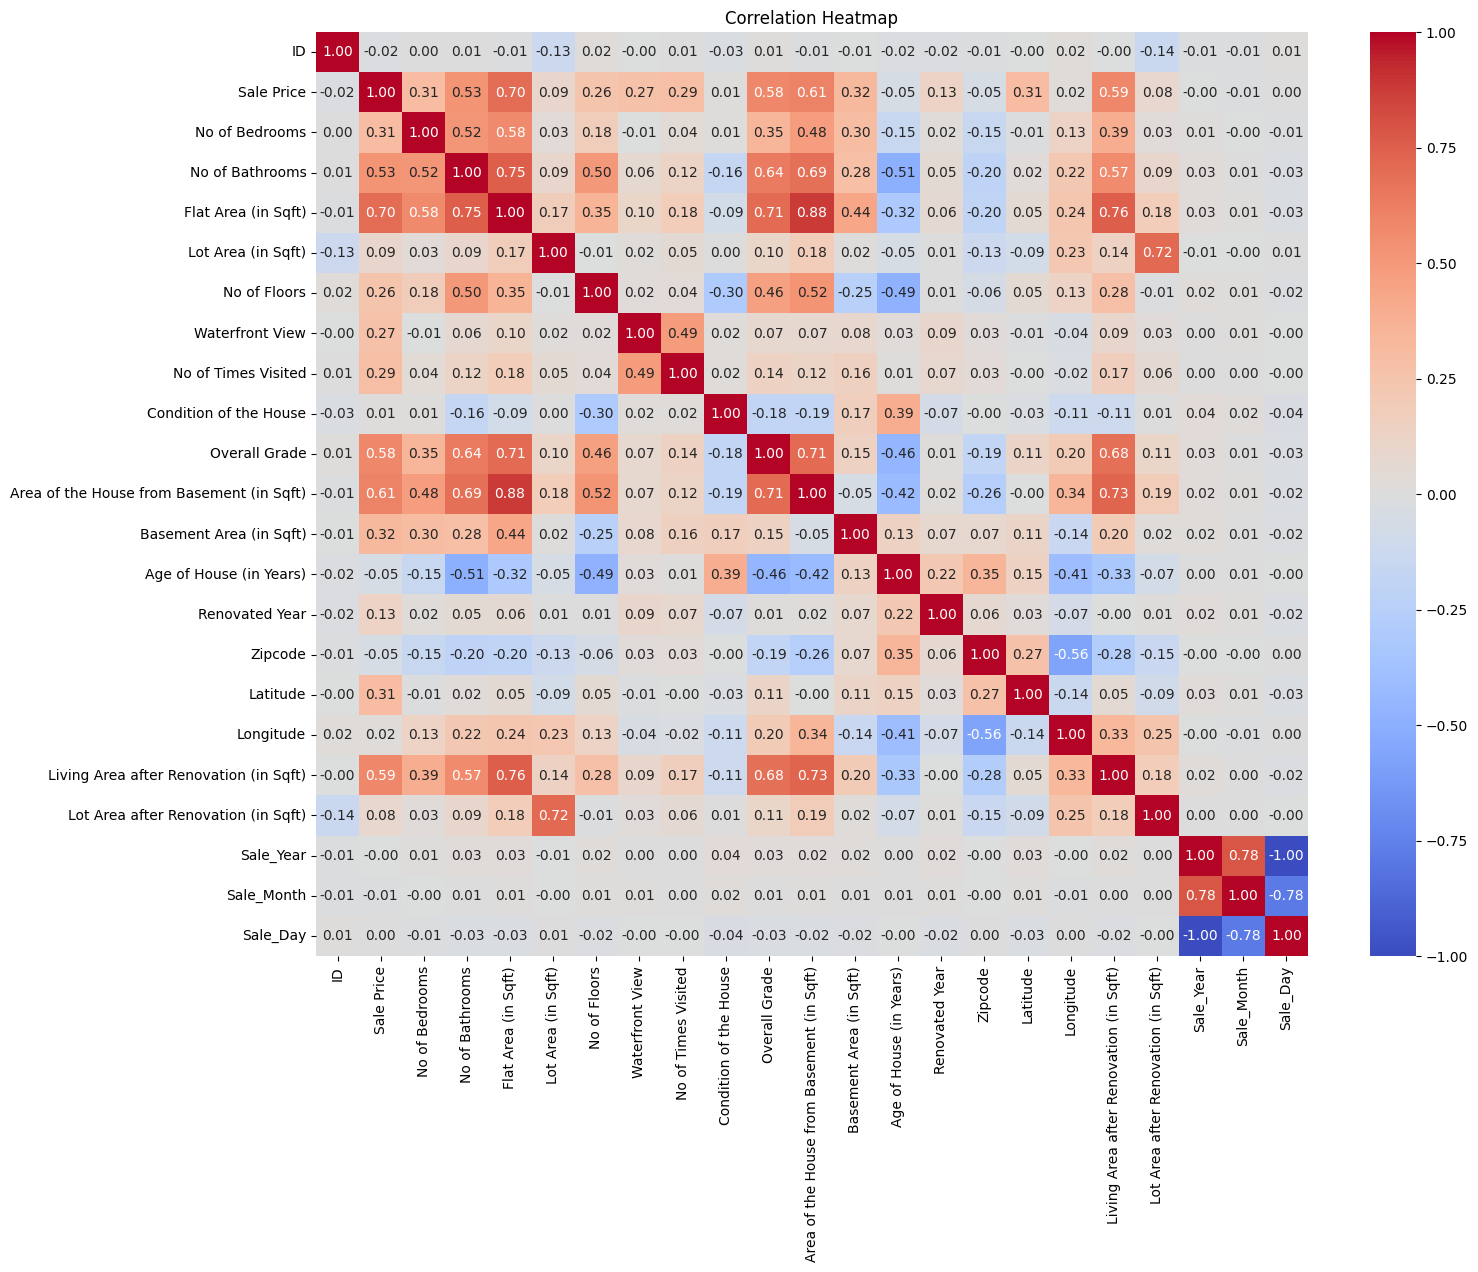

In [25]:
# Calculate correlation matrix

correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [26]:
# Select the chosen features

selected_features = [
    "No of Bedrooms",
    "No of Bathrooms",
    "Flat Area (in Sqft)",
    "Overall Grade",
    "Area of the House from Basement (in Sqft)"
]

X = df[selected_features]
y = df["Sale Price"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (21613, 5)
y shape: (21613,)


In [27]:
# Outlier handling using IQR clipping for selected features

for column in selected_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = df[column].clip(lower_bound, upper_bound)

print("Outlier clipping completed for selected features.")

Outlier clipping completed for selected features.


In [28]:
from sklearn.model_selection import train_test_split

X = df[selected_features]
y = df["Sale Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (17290, 5)
Testing data: (4323, 5)


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


## MODELS

In [30]:
#LR
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [31]:
# Predict Sale Price

y_pred_lr = lr_model.predict(X_test_scaled)

print(y_pred_lr[:5])

[ 533248.18605384  724636.13872937 1054755.27113166 1205139.92356499
  768838.36463383]


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression")
print("-------------------------")
print("MAE :", mae_lr)
print("MSE :", mse_lr)
print("RMSE:", rmse_lr)
print("R²  :", r2_lr)

Linear Regression
-------------------------
MAE : 169941.688314679
MSE : 84171375683.6137
RMSE: 290123.03542396234
R²  : 0.4438108172874995


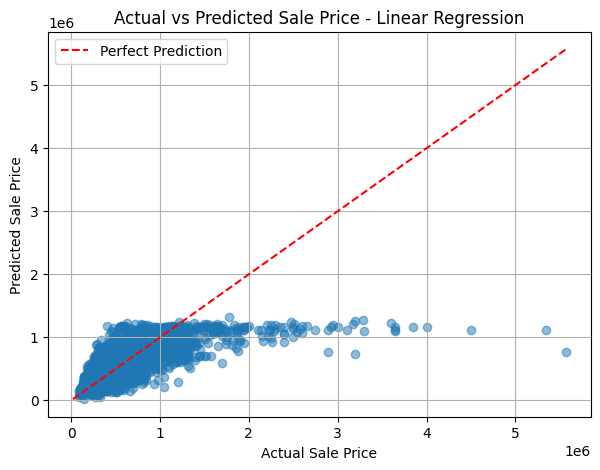

In [33]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_lr, alpha=0.5)

# Perfect prediction line
min_value = min(y_test.min(), y_pred_lr.min())
max_value = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - Linear Regression")
plt.legend()
plt.grid(True)

plt.show()

In [34]:
#KNN Regression

In [35]:
from sklearn.neighbors import KNeighborsRegressor

# Create the model
knn_model = KNeighborsRegressor(
    n_neighbors=5
)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN Regression model trained successfully.")

KNN Regression model trained successfully.


In [36]:
y_pred_knn = knn_model.predict(X_test_scaled)

print(y_pred_knn[:5])

[ 507785.4  524550.   985000.  1922000.   700400. ]


In [37]:
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mse_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN Regression")
print("-------------------------")
print("MAE :", mae_knn)
print("MSE :", mse_knn)
print("RMSE:", rmse_knn)
print("R²  :", r2_knn)

KNN Regression
-------------------------
MAE : 163899.49252833682
MSE : 70127373200.73991
RMSE: 264815.7344281867
R²  : 0.5366110382595626


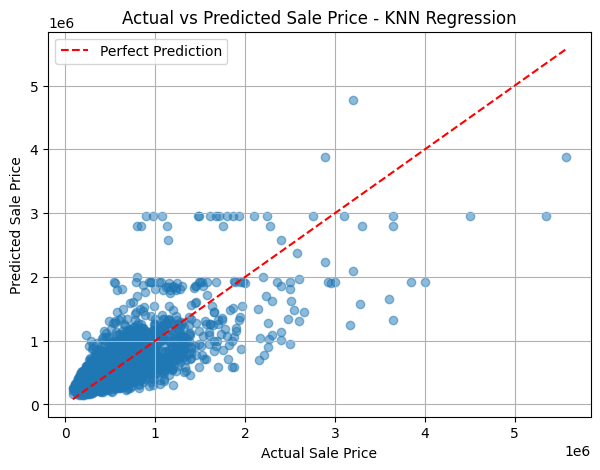

In [38]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_knn, alpha=0.5)

min_value = min(y_test.min(), y_pred_knn.min())
max_value = max(y_test.max(), y_pred_knn.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - KNN Regression")
plt.legend()
plt.grid(True)

plt.show()

In [39]:
#Support Vector Regression (SVR)

In [40]:
from sklearn.svm import SVR

# Create the model
svr_model = SVR(
    kernel="rbf",
    C=100,
    gamma="scale"
)

# Train the model
svr_model.fit(X_train_scaled, y_train)

print("SVR model trained successfully.")

SVR model trained successfully.


In [41]:
y_pred_svr = svr_model.predict(X_test_scaled)

print(y_pred_svr[:5])

[500042.98818114 543268.13130072 607260.00253766 580418.2905899
 578181.21673839]


In [42]:
mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print("SVR")
print("-------------------------")
print("MAE :", mae_svr)
print("MSE :", mse_svr)
print("RMSE:", rmse_svr)
print("R²  :", r2_svr)

SVR
-------------------------
MAE : 192946.1173625075
MSE : 128608553663.29918
RMSE: 358620.34753106127
R²  : 0.1501780056357973


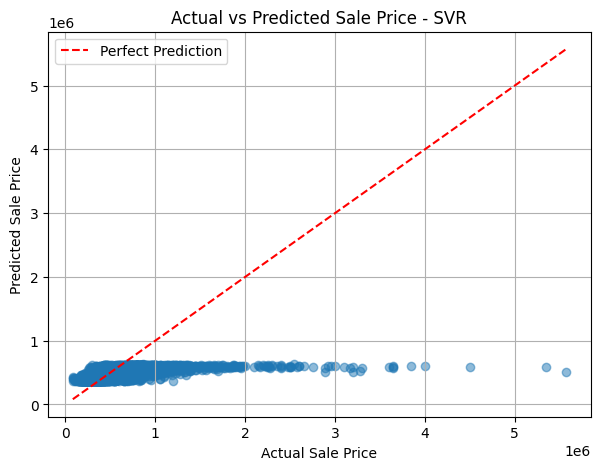

In [43]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_svr, alpha=0.5)

min_value = min(y_test.min(), y_pred_svr.min())
max_value = max(y_test.max(), y_pred_svr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - SVR")
plt.legend()
plt.grid(True)

plt.show()

In [44]:
#Random Forest Regression

In [45]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest Regression model trained successfully.")

Random Forest Regression model trained successfully.


In [46]:
y_pred_rf = rf_model.predict(X_test)

print(y_pred_rf[:5])

[ 401871.26095238  633731.          961579.25       2259919.39072341
  823112.        ]


In [47]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression")
print("-------------------------")
print("MAE :", mae_rf)
print("MSE :", mse_rf)
print("RMSE:", rmse_rf)
print("R²  :", r2_rf)

Random Forest Regression
-------------------------
MAE : 162898.39705015643
MSE : 73332814102.53578
RMSE: 270800.3214594395
R²  : 0.5154300662138587


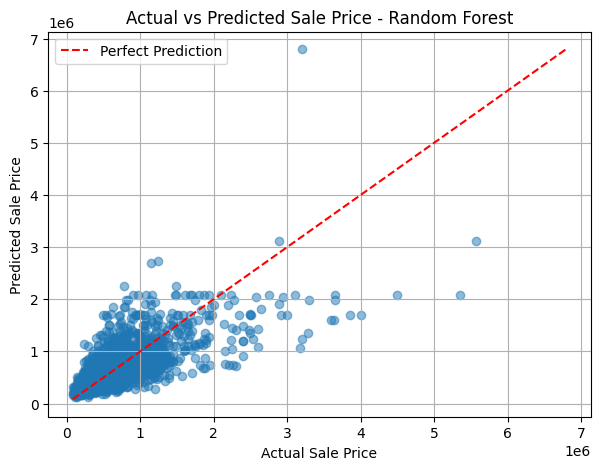

In [48]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_rf, alpha=0.5)

min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Price - Random Forest")
plt.legend()
plt.grid(True)

plt.show()

In [49]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "KNN Regressor",
        "SVR",
        "Random Forest Regressor"
    ],

    "MAE": [
        mae_lr,
        mae_knn,
        mae_svr,
        mae_rf
    ],

    "MSE": [
        mse_lr,
        mse_knn,
        mse_svr,
        mse_rf
    ],

    "RMSE": [
        rmse_lr,
        rmse_knn,
        rmse_svr,
        rmse_rf
    ],

    "R2 Score": [
        r2_lr,
        r2_knn,
        r2_svr,
        r2_rf
    ]
})

results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,169941.688315,8.417138e+10,290123.035424,0.443811
1,KNN Regressor,163899.492528,7.012737e+10,264815.734428,0.536611
2,SVR,192946.117363,1.286086e+11,358620.347531,0.150178
3,Random Forest Regressor,162898.397050,7.333281e+10,270800.321459,0.515430


In [50]:

results.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,MSE,RMSE,R2 Score
1,KNN Regressor,163899.492528,7.012737e+10,264815.734428,0.536611
3,Random Forest Regressor,162898.397050,7.333281e+10,270800.321459,0.515430
0,Linear Regression,169941.688315,8.417138e+10,290123.035424,0.443811
2,SVR,192946.117363,1.286086e+11,358620.347531,0.150178


In [51]:
joblib.dump(knn_model, "best_knn_regressor.pkl")

print("KNN Regressor saved successfully.")

KNN Regressor saved successfully.


In [52]:
joblib.dump(scaler, "knn_scaler.pkl")

print("Scaler saved successfully.")

Scaler saved successfully.


In [53]:
import joblib

knn_model = joblib.load("best_knn_regressor.pkl")
scaler = joblib.load("knn_scaler.pkl")

print("Model and scaler loaded successfully.")

Model and scaler loaded successfully.


In [54]:
new_house = pd.DataFrame({
    "No of Bedrooms": [3],
    "No of Bathrooms": [2.0],
    "Flat Area (in Sqft)": [1800],
    "Overall Grade": [7],
    "Area of the House from Basement (in Sqft)": [1000]
})

new_house

,No of Bedrooms,No of Bathrooms,Flat Area (in Sqft),Overall Grade,Area of the House from Basement (in Sqft)
0,3,2.0,1800,7,1000


In [55]:
new_house_scaled = scaler.transform(new_house)

In [56]:
predicted_price = knn_model.predict(new_house_scaled)

print("Predicted Sale Price:", predicted_price[0])

Predicted Sale Price: 636600.0


**Conclusion**
-Among the four regression models, KNN Regressor performs the best overall based on the highest R² score of 0.5366.
It also has the lowest MSE and lowest RMSE mong the models.
Random Forest has a slightly lower MAE than KNN, but its R² is lower at 0.5154.
Linear Regression performs moderately, while SVR performs the weakest.
Therefore, KNN Regressor is selected as the best baseline model for predicting Sale Price.